In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import math
import os
import sys
import torch
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from mappers import VoxelisedMapper, HashGridDensityMapper, BackgroundLoss, SmoothnessLoss
from surrogates import LossSurrogate, NormalizingFlow
from propagation import RossiPropagator, HighlandPropagator
from scheduler import GaussianLikelihoodScheduler
from callbacks import LossPlotCallback, MapperPlotCallback, ObservablesPlotCallback, LogProbPlotCallback
from constants import *

In [2]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.05
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
dataset = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_boiler.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_boiler.npy',
    selection = selection,
)
print (len(dataset))

13342849


In [19]:
scheduler = GaussianLikelihoodScheduler(
    dataset = dataset,
    # mapper = VoxelisedMapper(
    #     xlow = dataset.low,
    #     xhigh = dataset.high,
    #     ylow = LAMBDA_MIN,
    #     yhigh = LAMBDA_MAX,
    #     resolution = [32,32,32],
    #     initial_val = 1./X0s['Air'],
    #     lr = 1e-2,
    #     interpolate = True,
    #     accumulation = 10,
    # ),
    mapper = HashGridDensityMapper(
        xlow = dataset.low,
        xhigh = dataset.high,
        ylow = LAMBDA_MIN,
        yhigh = LAMBDA_MAX,
        feature_dim = 2,
        neurons = [128],
        activation = torch.nn.GELU,
        resolutions = [16,32,64],
        interpolate = True,
        lr = 1e-3,
        accumulation = None,
    ),
    mapper_losses = [
        BackgroundLoss(
            N = 5000,
            weight = 1e-3,
            target_density = 1./X0s['Air'],
        ),
        SmoothnessLoss(
            N = 5000,
            weight = 1,
            eps = 0.01,
            p = 1,
        ),
    ],
    scheduler_params = dict(
        mode = 'min',
        factor = 0.1,
        patience = 200,
        threshold = 0.0001,
        threshold_mode = 'rel',
        cooldown = 100,
        min_lr = 1e-6,
    ),
    device = 'cuda:3',
    batch_size = 5000,
    propagator = HighlandPropagator(
        step_size = 0.005, # m
    ),
    callbacks = [
        LossPlotCallback(frequency=50,scale = 'symlog'),
        MapperPlotCallback(
            low = dataset.low,
            high = dataset.high,
            xs = [1.5],
            ys = [1.],
            zs = [1.],
            points = 100,
            frequency = 50,
            log = False,
        ),
    ],
)
print (scheduler.mapper)
print (scheduler.scheduler)

HashGridDensityMapper(
  (grids): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x2x16x16x16 (cuda:3)]
      (1): Parameter containing: [torch.float32 of size 1x2x32x32x32 (cuda:3)]
      (2): Parameter containing: [torch.float32 of size 1x2x64x64x64 (cuda:3)]
  )
  (decoder): MLP(
    (layers): Sequential(
      (0): Linear(in_features=6, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)


{'Air': 0.003290556103981573, 'H2': 0.11235955056179775, 'H2O': 2.770083102493075, 'C': 5.181347150259067, 'Ca': 9.596928982725528, 'Si': 10.672358591248665, 'Al': 11.23974373384287, 'Fe': 56.91519635742744, 'Cu': 69.63788300835655, 'Pb': 178.1895937277263, 'W': 285.38812785388126, 'U': 315.8559696778269}


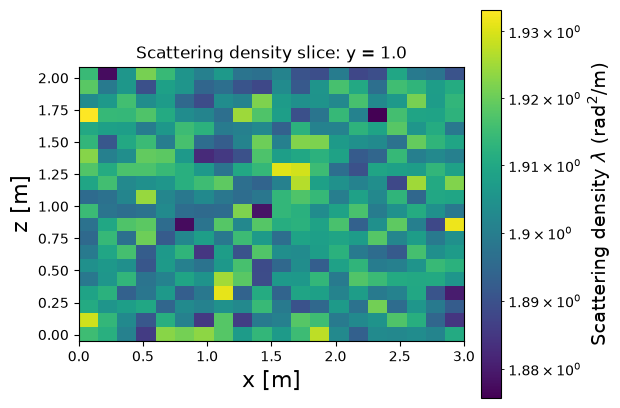

In [20]:
fig = scheduler.mapper.plot_slice(
    direction = 'y',
    value = 1.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
    show_materials = False,
    log = True,
)
print ({name: 1/X0 for name,X0 in X0s.items()})
plt.show()

In [21]:
# # scheduler.n_samples=1
# sim_datasets,idx = scheduler.propagate(1000,no_grad=True)

# fig = scheduler.callbacks[2].on_observables_end(None,sim_datasets[0].observables,dataset.observables,dataset.observable_names)
# plt.show()

# sim_datasets[0].plot_3d(torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10, threshold=0.0001, threshold_mode='rel', cooldown=0, min_lr=0, eps=1e-08)
#     N = 20,
#     arrow_scale=0.5,
#     show_direction=True,losses
#     show_path=True,                                                                                                                                                                                              
# )
# plt.show()

In [24]:
scheduler.mapper.set_lr(1e-4)

Iteration 1/10000 [ 0.01]% - LR = 1.000e-04
Loss : -24.229 = -24.797 (Mapping) + 0.517 (Background) + 0.051 (Smoothness)
Iteration 2/10000 [ 0.02]% - LR = 1.000e-04
Loss : -24.159 = -24.732 (Mapping) + 0.522 (Background) + 0.051 (Smoothness)
Iteration 3/10000 [ 0.03]% - LR = 1.000e-04
Loss : -23.961 = -24.526 (Mapping) + 0.514 (Background) + 0.051 (Smoothness)
Iteration 4/10000 [ 0.04]% - LR = 1.000e-04


[W1028 11:25:56.623324709 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 3 while trying to allocate 1912602624 bytes (free: 127664128, total: 15637086208).


Loss : -24.435 = -25.009 (Mapping) + 0.523 (Background) + 0.051 (Smoothness)
Iteration 5/10000 [ 0.05]% - LR = 1.000e-04
Loss : -21.737 = -22.298 (Mapping) + 0.510 (Background) + 0.051 (Smoothness)
Iteration 6/10000 [ 0.06]% - LR = 1.000e-04
Loss : -24.526 = -25.088 (Mapping) + 0.511 (Background) + 0.051 (Smoothness)
Iteration 7/10000 [ 0.07]% - LR = 1.000e-04
Loss : -23.783 = -24.353 (Mapping) + 0.520 (Background) + 0.051 (Smoothness)
Iteration 8/10000 [ 0.08]% - LR = 1.000e-04
Loss : -24.145 = -24.712 (Mapping) + 0.516 (Background) + 0.051 (Smoothness)
Iteration 9/10000 [ 0.09]% - LR = 1.000e-04
Loss : -23.872 = -24.439 (Mapping) + 0.516 (Background) + 0.050 (Smoothness)
Iteration 10/10000 [ 0.10]% - LR = 1.000e-04
Loss : -21.074 = -21.642 (Mapping) + 0.516 (Background) + 0.051 (Smoothness)
Iteration 11/10000 [ 0.11]% - LR = 1.000e-04
Loss : -23.730 = -24.293 (Mapping) + 0.512 (Background) + 0.051 (Smoothness)
Iteration 12/10000 [ 0.12]% - LR = 1.000e-04
Loss : -23.799 = -24.363 (Map

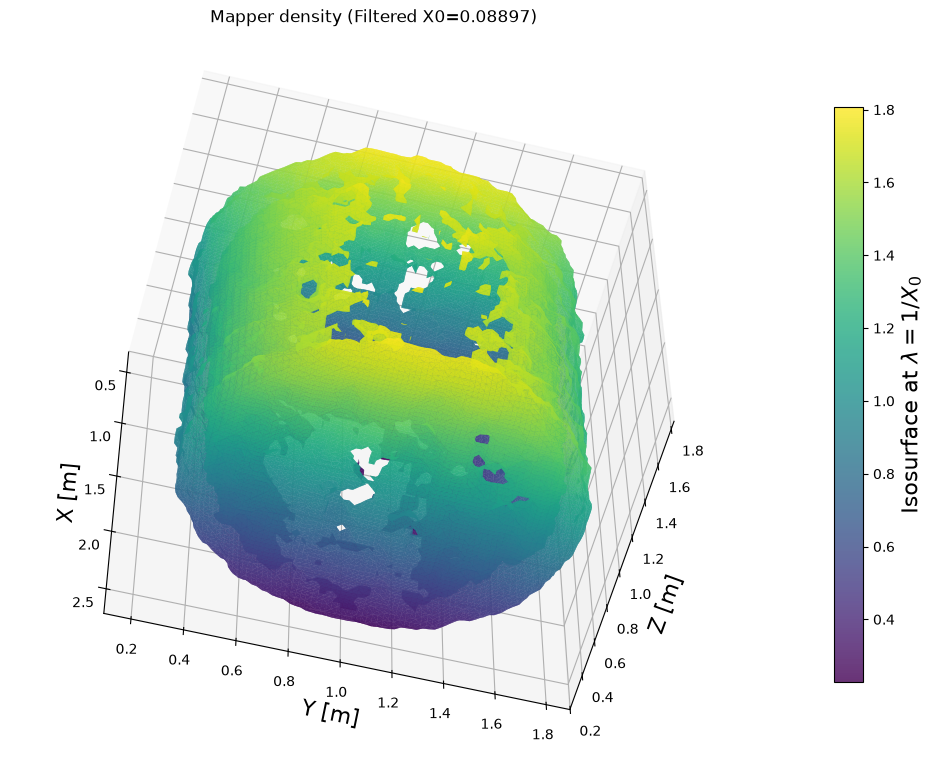

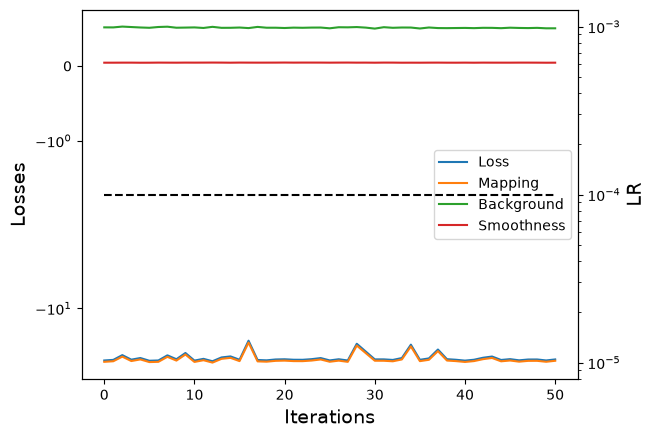

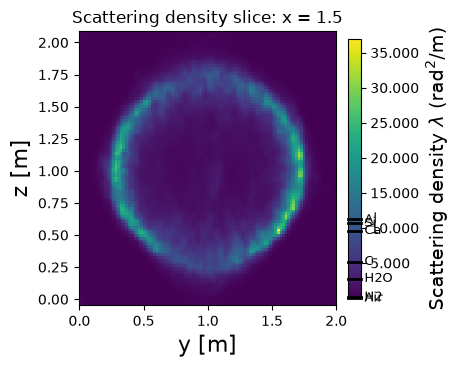

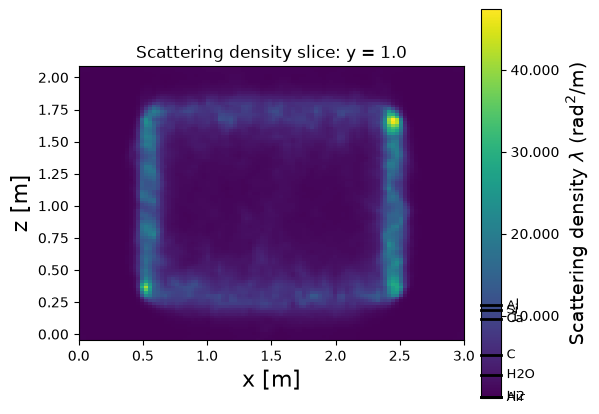

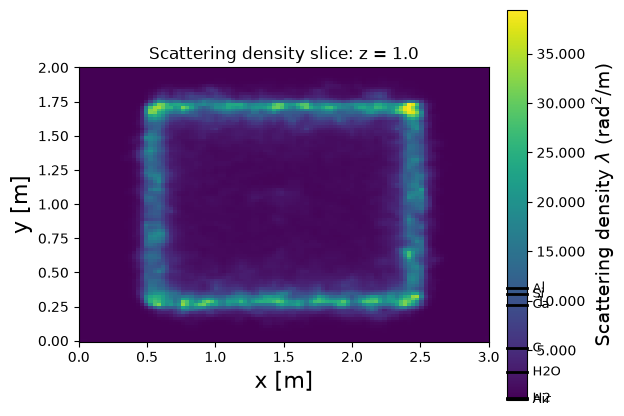

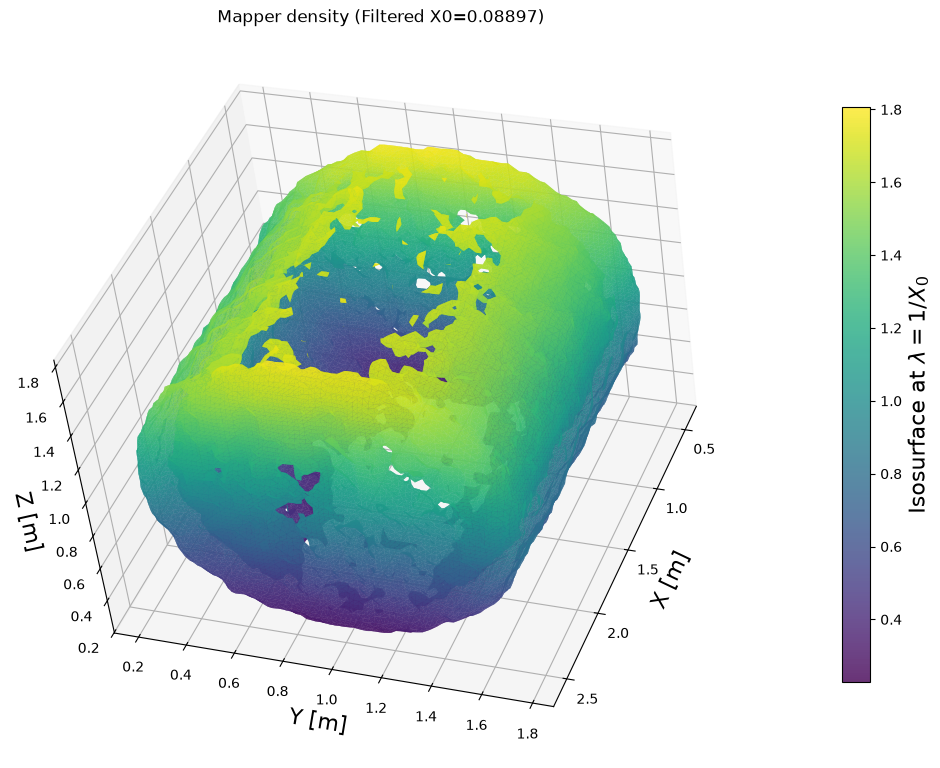

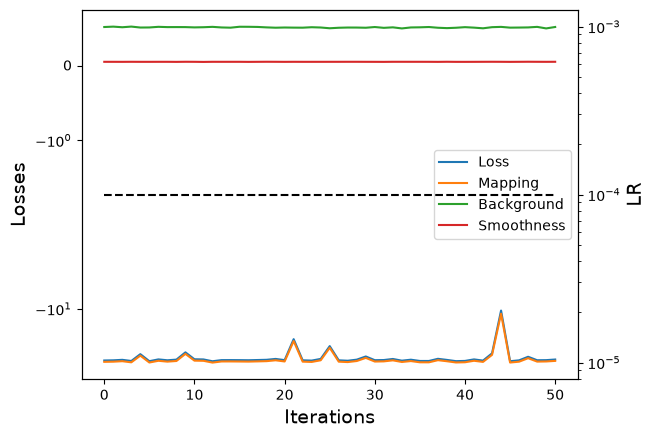

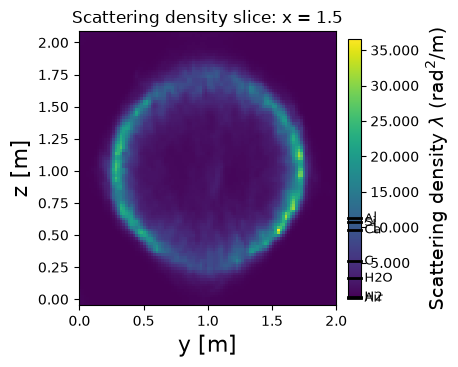

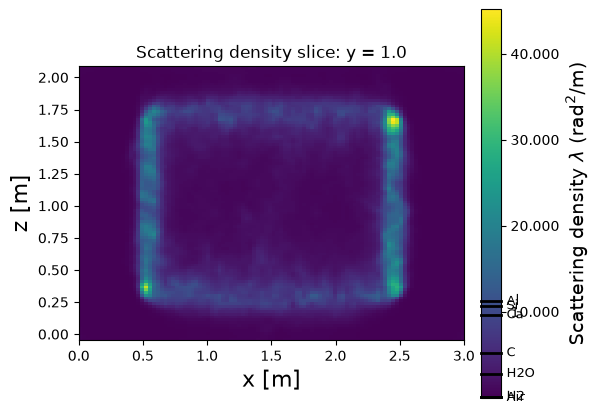

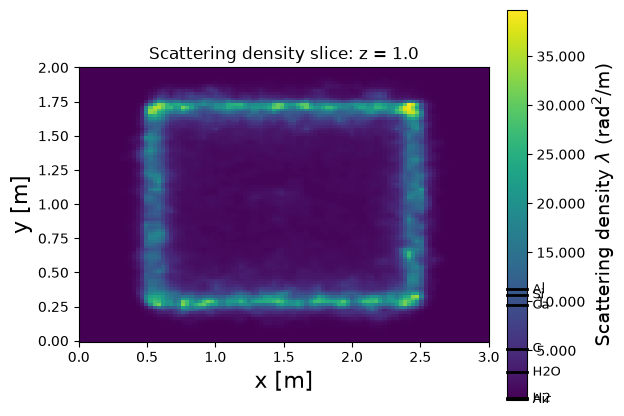

Iteration 52/10000 [ 0.52]% - LR = 1.000e-04
Loss : -23.810 = -24.367 (Mapping) + 0.507 (Background) + 0.050 (Smoothness)
Iteration 53/10000 [ 0.53]% - LR = 1.000e-04
Loss : -24.267 = -24.824 (Mapping) + 0.507 (Background) + 0.050 (Smoothness)
Iteration 54/10000 [ 0.54]% - LR = 1.000e-04
Loss : -22.881 = -23.440 (Mapping) + 0.509 (Background) + 0.050 (Smoothness)
Iteration 55/10000 [ 0.55]% - LR = 1.000e-04
Loss : -24.366 = -24.926 (Mapping) + 0.508 (Background) + 0.051 (Smoothness)
Iteration 56/10000 [ 0.56]% - LR = 1.000e-04
Loss : -23.986 = -24.547 (Mapping) + 0.510 (Background) + 0.051 (Smoothness)
Iteration 57/10000 [ 0.57]% - LR = 1.000e-04
Loss : -24.499 = -25.065 (Mapping) + 0.515 (Background) + 0.051 (Smoothness)
Iteration 58/10000 [ 0.58]% - LR = 1.000e-04
Loss : -23.485 = -24.039 (Mapping) + 0.503 (Background) + 0.051 (Smoothness)
Iteration 59/10000 [ 0.59]% - LR = 1.000e-04
Loss : -23.893 = -24.448 (Mapping) + 0.504 (Background) + 0.050 (Smoothness)
Iteration 60/10000 [ 0.6

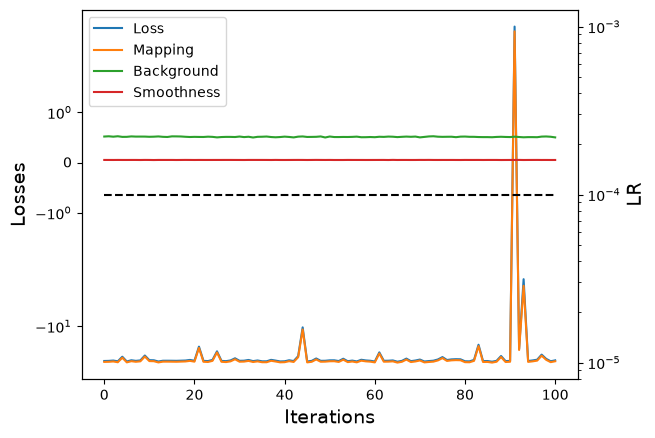

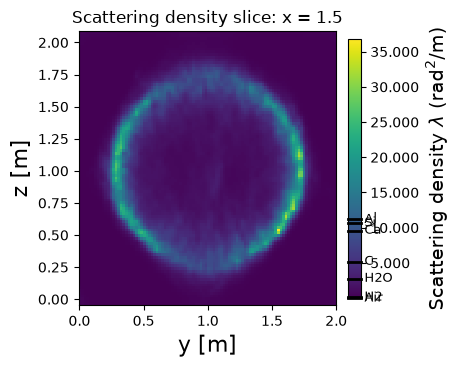

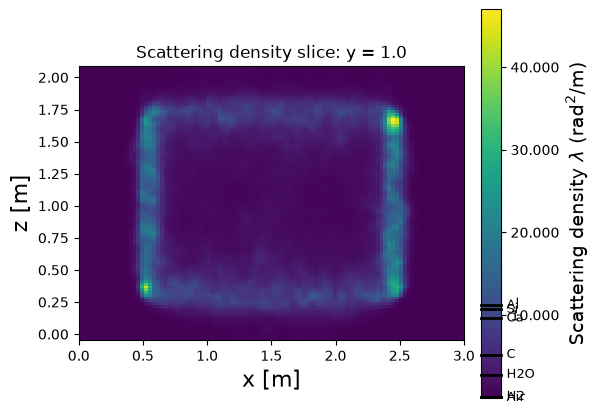

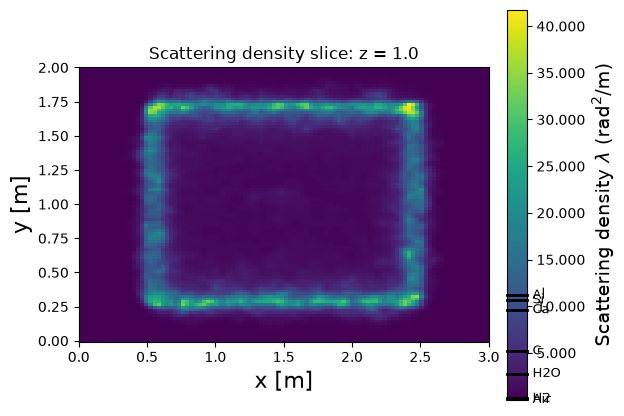

Iteration 102/10000 [ 1.02]% - LR = 1.000e-04
Loss : -24.371 = -24.929 (Mapping) + 0.506 (Background) + 0.051 (Smoothness)
Iteration 103/10000 [ 1.03]% - LR = 1.000e-04
Loss : -24.680 = -25.228 (Mapping) + 0.497 (Background) + 0.051 (Smoothness)
Iteration 104/10000 [ 1.04]% - LR = 1.000e-04
Loss : -24.476 = -25.036 (Mapping) + 0.510 (Background) + 0.050 (Smoothness)
Iteration 105/10000 [ 1.05]% - LR = 1.000e-04
Loss : -23.008 = -23.564 (Mapping) + 0.505 (Background) + 0.051 (Smoothness)
Iteration 106/10000 [ 1.06]% - LR = 1.000e-04
Loss : -23.595 = -24.152 (Mapping) + 0.506 (Background) + 0.051 (Smoothness)
Iteration 107/10000 [ 1.07]% - LR = 1.000e-04
Loss : -24.420 = -24.969 (Mapping) + 0.498 (Background) + 0.051 (Smoothness)
Iteration 108/10000 [ 1.08]% - LR = 1.000e-04
Loss : -24.172 = -24.731 (Mapping) + 0.509 (Background) + 0.051 (Smoothness)
Iteration 109/10000 [ 1.09]% - LR = 1.000e-04
Loss : -24.333 = -24.892 (Mapping) + 0.509 (Background) + 0.051 (Smoothness)
Iteration 110/10

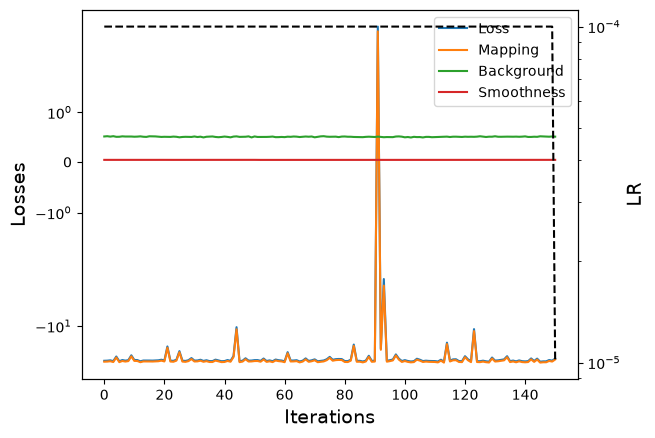

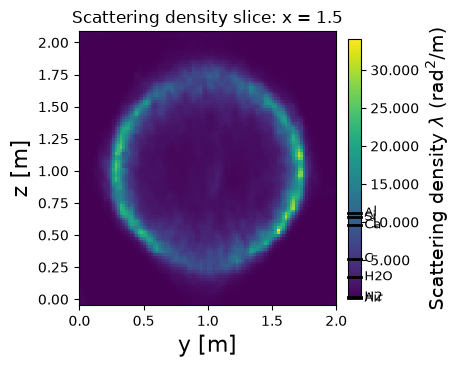

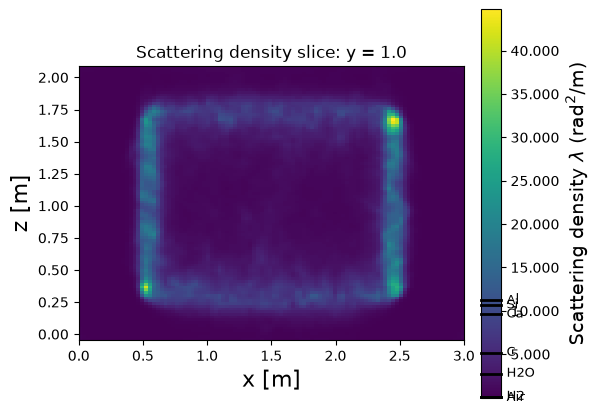

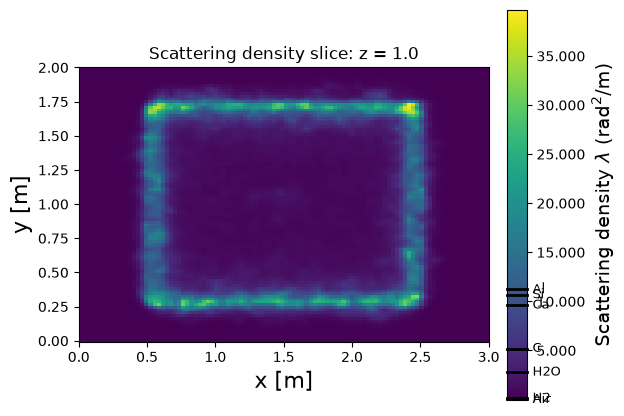

Iteration 152/10000 [ 1.52]% - LR = 1.000e-05
Loss : 49.931 = 49.367 (Mapping) + 0.513 (Background) + 0.051 (Smoothness)
Iteration 153/10000 [ 1.53]% - LR = 1.000e-05
Loss : -23.387 = -23.956 (Mapping) + 0.518 (Background) + 0.052 (Smoothness)
Iteration 154/10000 [ 1.54]% - LR = 1.000e-05
Loss : -24.445 = -25.016 (Mapping) + 0.520 (Background) + 0.051 (Smoothness)
Iteration 155/10000 [ 1.55]% - LR = 1.000e-05
Loss : -23.575 = -24.138 (Mapping) + 0.511 (Background) + 0.052 (Smoothness)
Iteration 156/10000 [ 1.56]% - LR = 1.000e-05


KeyboardInterrupt: 

In [27]:
%matplotlib inline
scheduler.optimize(n_iterations=10000)

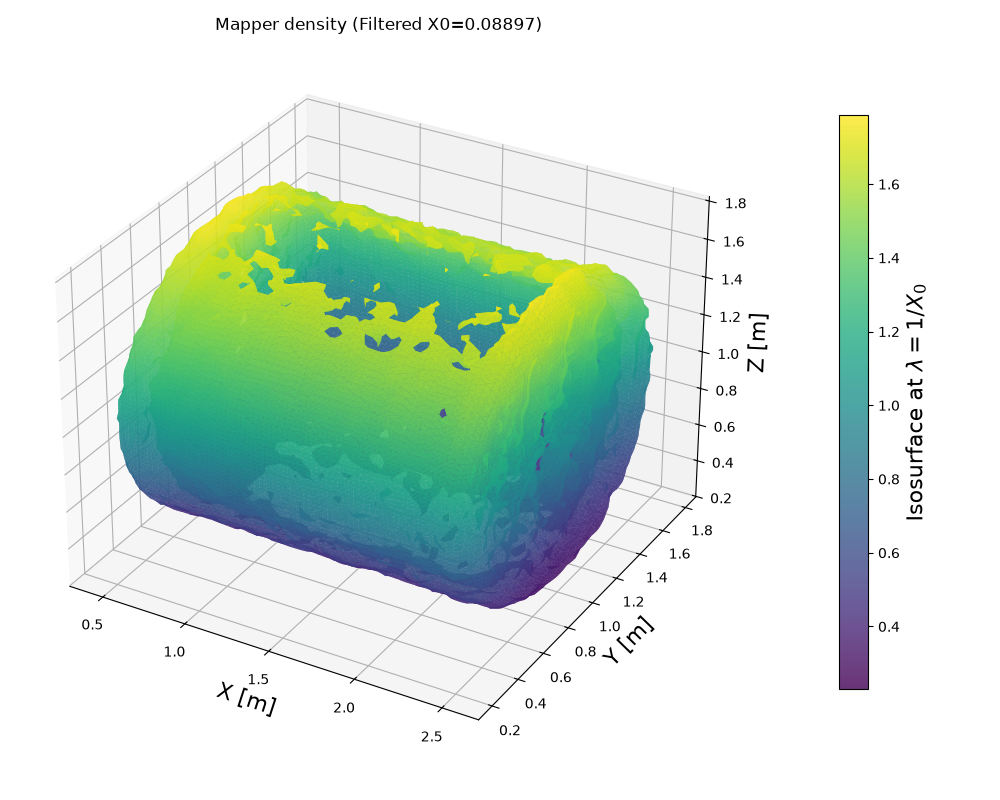

In [31]:
%matplotlib widget
scheduler.mapper.plot(
    low = dataset.low,
    high = dataset.high,
    X0 = X0s['Al'],
    plot_type = 'surface',
    points = 100,
)
plt.show()

In [ ]:
scheduler.mapper.print_global_resolution_importance()

In [30]:
plt.close('all')

In [ ]:
fig = scheduler.mapper.plot_slice(
    direction = 'z',
    value = 1.0,
    low = [0.5,0.5],
    high = [1.5,1.5],
    points = 100,
    batch_size = 5000,
)
plt.show()

In [ ]:
fig = scheduler.mapper.plot(
    X0 = X0s['Ca'],
    low = dataset.low,
    high = dataset.high,
    points = 100,
    batch_size = 5000,
    plot_type = 'surface',
    alpha = 0.5,
)
plt.show()

In [ ]:
scheduler.callbacks[0].plot(iteration=None)

In [ ]:
scheduler.callbacks[1].log = False
scheduler.callbacks[1].plot(iteration=None,mapper=scheduler.mapper)

In [ ]:
scheduler.callbacks[1].log = True
scheduler.callbacks[1].plot(iteration=None,mapper=scheduler.mapper)

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',self.propagate(batch_size)
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
scheduler.run(n_iterations=100,batch_size=256)

In [ ]:
scheduler.surrogate.validate_model(batch_size=1000)

In [ ]:
observables = positions_to_observables(
    ri = ri,
    rf = rf,
    di = di,
    df = df,
    lo = dataset.low,
    hi = dataset.high,
)
observables = torch.stack(observables,dim=1)
conditions = torch.cat([ri,di],dim=1)


In [ ]:
fig = scheduler.compare_observables(observables.detach())
plt.show()